In [1]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


In [2]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PAPER = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper")
VOCR_CSV = PAPER / "data" / "vocr_contributions.csv"
STEADY_CSV = PAPER / "data" / "hox_nox_steady_state.csv"
VOC_TABLE = PAPER / "code" / "airborne" / "config" / "Xu2021_VOCs_clean.csv"

AGE_BINS_H = [0, 1, 2, 3, 4, 6, 8, 12, 18, 42]

CLASS_ORDER = [
    "OVOCs",
    "Furans",
    "CO",
    "Oxy-aromatics",
    "Alkane/Alkene",
    "Red-aromatics",
]
CLASS_LABELS = {
    "OVOCs": "OVOCs",
    "Furans": "Furans",
    "CO": "CO",
    "Oxy-aromatics": "Oxygenated aromatics",
    "Alkane/Alkene": "Alkanes and alkenes",
    "Red-aromatics": "Reduced aromatics",
}
CLASS_COLORS = {
    "OVOCs": "#0072B2",
    "Furans": "#E69F00",
    "CO": "#7A7A7A",
    "Oxy-aromatics": "#D55E00",
    "Alkane/Alkene": "tab:green",
    "Red-aromatics": "#CC79A7",
}


In [3]:
vocr = pd.read_csv(VOCR_CSV, parse_dates=["timestamp"])
steady = pd.read_csv(
    STEADY_CSV,
    usecols=["timestamp", "smoke_age"],
    parse_dates=["timestamp"],
)
df = vocr.merge(steady, on="timestamp", how="inner")
df = df.loc[df["smoke_age"].notna() & (df["VOCR"] > 0)].copy()
df["smoke_age_h"] = df["smoke_age"] / 3600.0

species = [c for c in vocr.columns if c not in ("timestamp", "VOCR")]
class_of = (
    pd.read_csv(VOC_TABLE, usecols=["VOC", "Class"])
    .drop_duplicates("VOC")
    .set_index("VOC")["Class"]
)
missing = sorted(set(species) - set(class_of.index))
if missing:
    raise ValueError(f"No class for {missing}")

groups = {}
for sp in species:
    groups.setdefault(class_of[sp], []).append(sp)
by_class = pd.DataFrame({name: df[cols].sum(axis=1) for name, cols in groups.items()})
by_class = by_class[CLASS_ORDER]
fraction = by_class.div(by_class.sum(axis=1), axis=0)

df["age_bin"] = pd.cut(df["smoke_age_h"], AGE_BINS_H, right=True)
binned = fraction.groupby(df["age_bin"], observed=True).mean()
summary = pd.DataFrame(
    {
        "n": df.groupby("age_bin", observed=True).size(),
        "mean_VOCR": df.groupby("age_bin", observed=True)["VOCR"].mean(),
    }
)
summary = summary.join(binned)
summary


,n,mean_VOCR,OVOCs,Furans,CO,Oxy-aromatics,Alkane/Alkene,Red-aromatics
age_bin,,,,,,,,
"(0, 1]",7057,20.105362,0.343655,0.234879,0.142509,0.164195,0.088939,0.025824
"(1, 2]",13246,20.025190,0.357771,0.248068,0.148151,0.165270,0.052413,0.028326
"(2, 3]",14087,15.840883,0.375987,0.247096,0.166979,0.155028,0.028681,0.026229
"(3, 4]",11282,7.351047,0.416225,0.213604,0.196150,0.124788,0.025046,0.024187
"(4, 6]",9236,3.058396,0.439332,0.184101,0.225900,0.101116,0.026008,0.023542
"(6, 8]",3667,2.389163,0.424979,0.176279,0.251344,0.096480,0.023530,0.027389
"(8, 12]",2599,2.580065,0.426009,0.149102,0.294890,0.081310,0.022394,0.026294
"(12, 18]",3915,1.203439,0.332111,0.065029,0.539748,0.042190,0.008719,0.012204
"(18, 42]",11153,2.128996,0.390607,0.104673,0.407388,0.065870,0.014266,0.017197


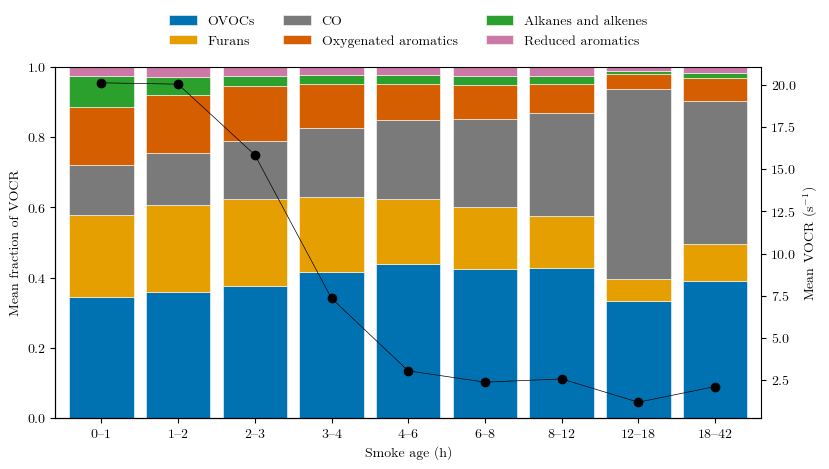

In [4]:
fig, ax = plt.subplots(figsize=(8.4, 4.8))
x = np.arange(len(binned))
bottom = np.zeros(len(binned))
for name in CLASS_ORDER:
    values = binned[name].to_numpy()
    ax.bar(
        x,
        values,
        bottom=bottom,
        width=0.84,
        color=CLASS_COLORS[name],
        edgecolor="white",
        linewidth=0.4,
        label=CLASS_LABELS[name],
        zorder=2,
    )
    bottom += values

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{int(interval.left)}\u2013{int(interval.right)}" for interval in binned.index]
)
ax.set_xlim(-0.6, len(binned) - 0.4)
ax.set_ylim(0, 1)
ax.set_xlabel("Smoke age (h)")
ax.set_ylabel("Mean fraction of VOCR")
ax.legend(
    frameon=False,
    ncol=3,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax1 = ax.twinx()
ax1.set_ylabel("Mean VOCR (s$^{-1}$)")
ax1.plot(x, summary["mean_VOCR"].values, 'o-', color="black", lw=0.5)

fig.tight_layout()
plt.show()


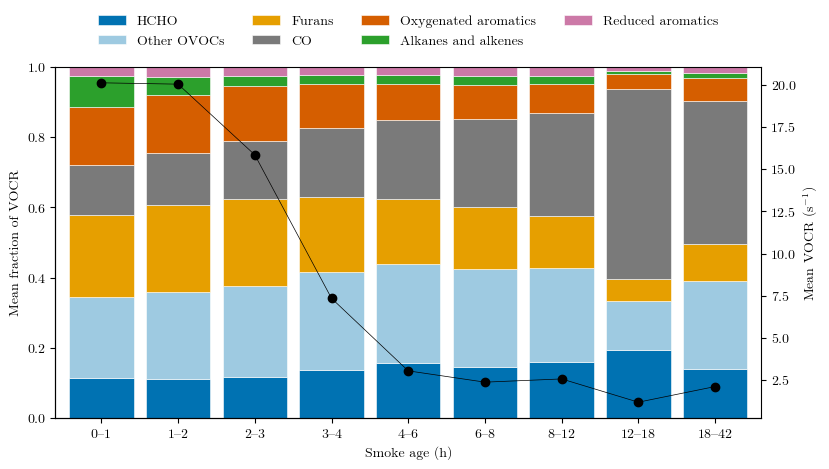

In [5]:
split_order = [
    "HCHO",
    "Other OVOCs",
    "Furans",
    "CO",
    "Oxy-aromatics",
    "Alkane/Alkene",
    "Red-aromatics",
]
split_labels = {
    **CLASS_LABELS,
    "HCHO": "HCHO",
    "Other OVOCs": "Other OVOCs",
}
split_colors = {
    **CLASS_COLORS,
    "HCHO": "#0072B2",
    "Other OVOCs": "#9ECAE1",
}

other_ovocs = [sp for sp in groups["OVOCs"] if sp != "HCHO"]
by_split = by_class.drop(columns="OVOCs").copy()
by_split["HCHO"] = df["HCHO"]
by_split["Other OVOCs"] = df[other_ovocs].sum(axis=1)
by_split = by_split[split_order]
fraction_split = by_split.div(by_split.sum(axis=1), axis=0)
binned_split = fraction_split.groupby(df["age_bin"], observed=True).mean()

fig, ax = plt.subplots(figsize=(8.4, 4.8))
x = np.arange(len(binned_split))
bottom = np.zeros(len(binned_split))
for name in split_order:
    values = binned_split[name].to_numpy()
    ax.bar(
        x,
        values,
        bottom=bottom,
        width=0.84,
        color=split_colors[name],
        edgecolor="white",
        linewidth=0.4,
        label=split_labels[name],
        zorder=2,
    )
    bottom += values

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{int(interval.left)}\u2013{int(interval.right)}" for interval in binned_split.index]
)
ax.set_xlim(-0.6, len(binned_split) - 0.4)
ax.set_ylim(0, 1)
ax.set_xlabel("Smoke age (h)")
ax.set_ylabel("Mean fraction of VOCR")
ax.legend(
    frameon=False,
    ncol=4,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax1 = ax.twinx()
ax1.set_ylabel("Mean VOCR (s$^{-1}$)")
ax1.plot(x, summary["mean_VOCR"].values, "o-", color="black", lw=0.5)

fig.tight_layout()
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/figs05.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/figs05.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
